# Descomposicion de serie de tiempo en componentes de Tendencia, estacional y residual

Número de observaciones: 4320
Número de columnas: 5

Periodo analizado:
Inicio: 2026-11-03 14:06:01
Final : 2026-11-06 14:05:00

Variables que serán graficadas:
--------------------------------
1 T

Total de variables: 1


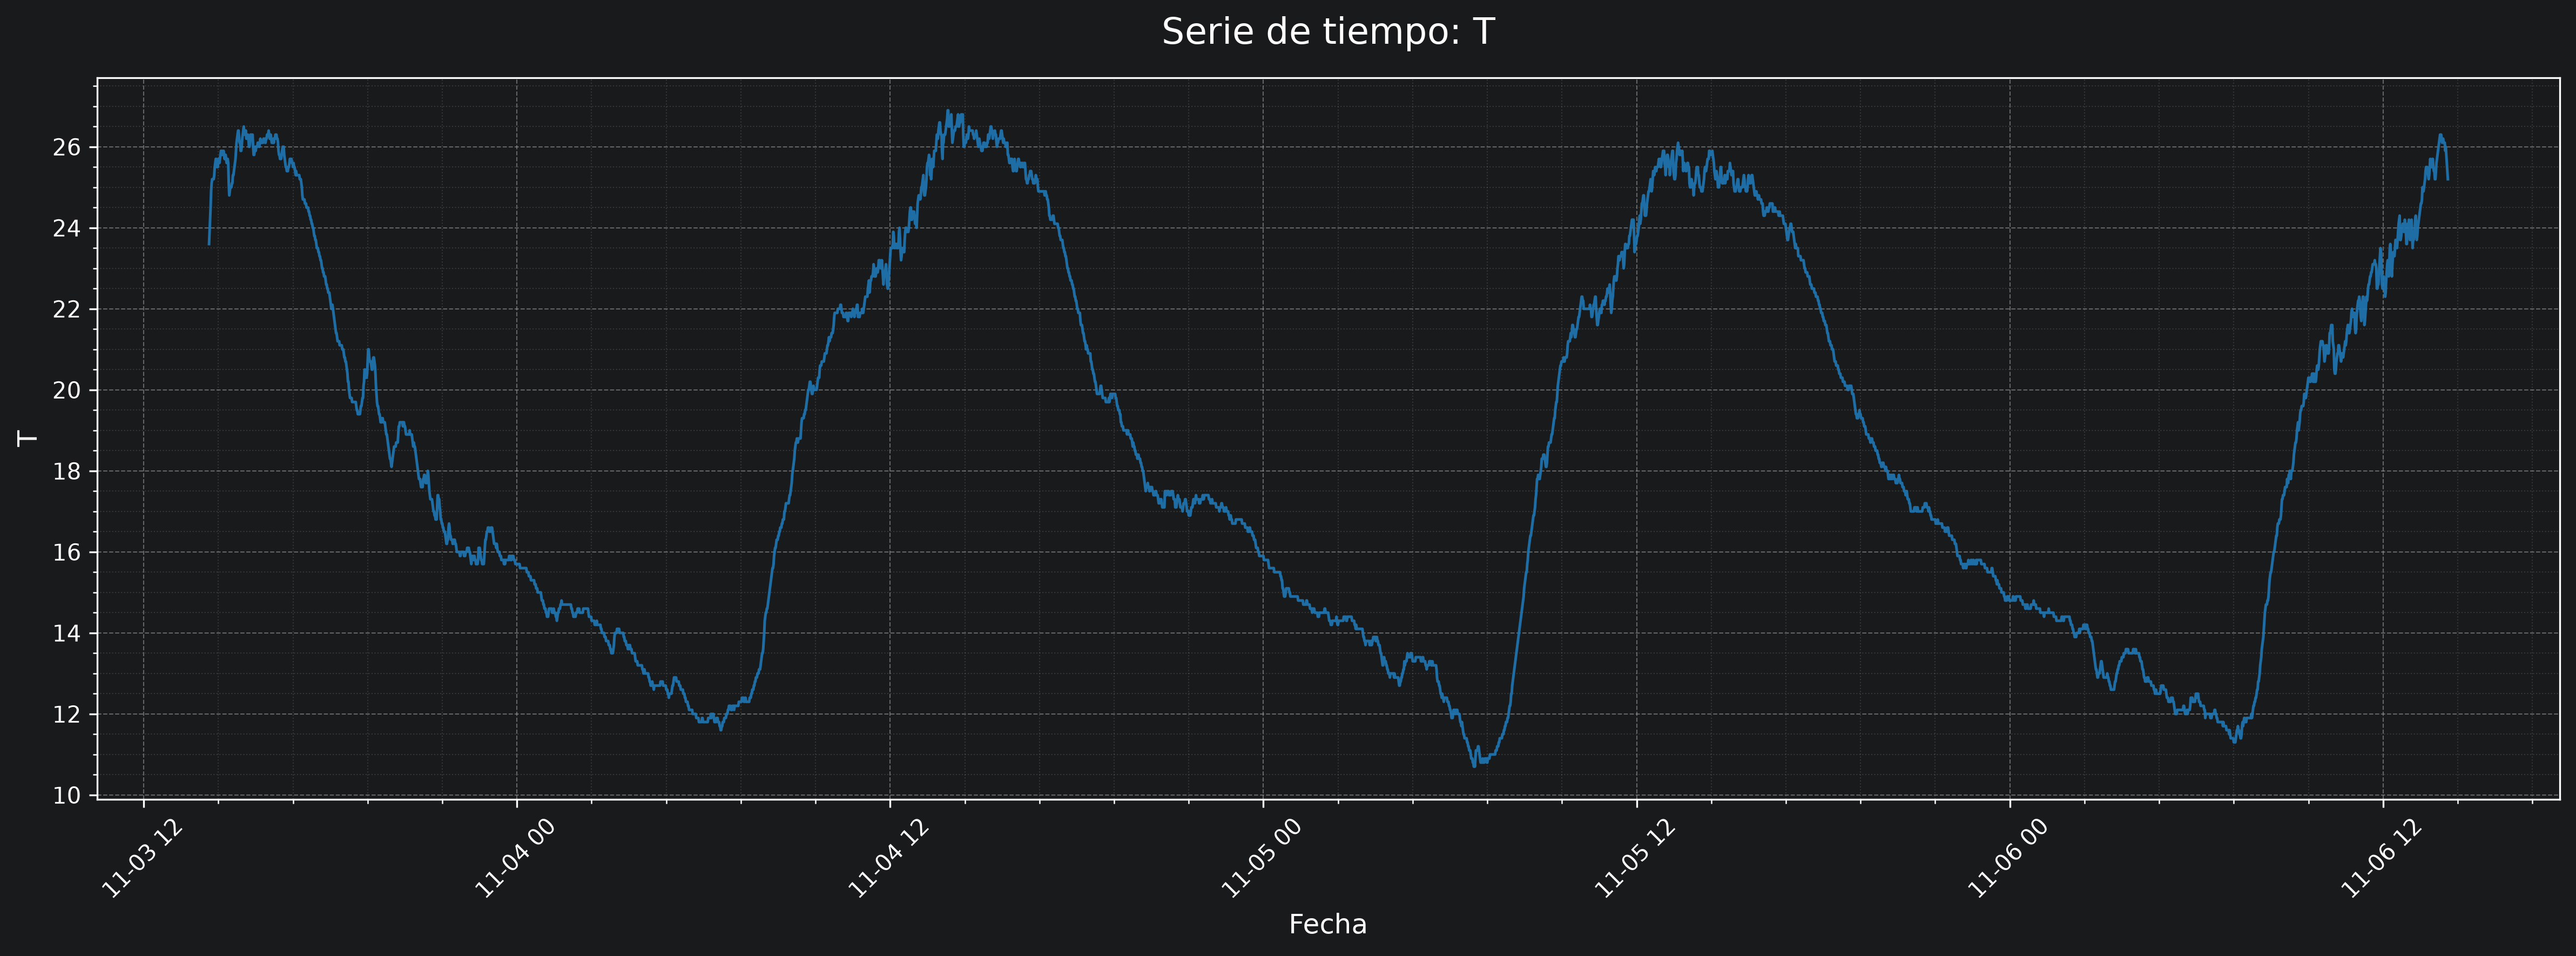

In [9]:
# ================================================================
# GRAFICACIÓN DE SERIES DE TIEMPO
# Datos meteorológicos - Weather Underground
# Estación PROTOTIPO
# ================================================================

import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------
# 1. CARGAR ARCHIVO EXCEL
# ------------------------------------------------
# Leer CSV
df = pd.read_csv("../data/datos_clima.csv")
print("Número de observaciones:", len(df))
print("Número de columnas:", len(df.columns))

# ------------------------------------------------
# 2. CONVERTIR FECHA Y HORA
# ------------------------------------------------

df['datetime'] = pd.to_datetime(df['datetime'], dayfirst=True)

# Ordenar cronológicamente
df = df.sort_values('datetime')

print("\nPeriodo analizado:")
print("Inicio:", df['datetime'].min())
print("Final :", df['datetime'].max())


# ------------------------------------------------
# 3. VARIABLES QUE NO SE GRAFICARÁN
# ------------------------------------------------

columnas_excluir = [
    'Fecha',
    'Hora',
    'H',
]


# ------------------------------------------------
# 4. SELECCIONAR VARIABLES NUMÉRICAS
# ------------------------------------------------

variables = [
    columna for columna in df.select_dtypes(include='number').columns
    if columna not in columnas_excluir
]

print("\nVariables que serán graficadas:")
print("--------------------------------")

for i, variable in enumerate(variables, start=1):
    print(i, variable)

print("\nTotal de variables:", len(variables))


# ------------------------------------------------
# 5. GRAFICAR CADA SERIE DE TIEMPO
# ------------------------------------------------

for variable in variables:
    plt.figure(figsize=(16, 6), dpi=300)

    plt.plot(
        df['datetime'],
        df[variable],
        linewidth=1.2, # Ligeramente más grueso para que destaque en alta resolución
        color='#1f77b4',
        alpha=0.9
    )

    plt.title(
        f'Serie de tiempo: {variable}',
        fontsize=16,
        pad=15 # Separación extra del título
    )

    plt.xlabel('Fecha', fontsize=12)
    plt.ylabel(variable, fontsize=12)

    # Cuadrícula principal (mayor) y secundaria (menor) para más detalle
    plt.grid(True, which='major', alpha=0.5, linestyle='--')
    plt.grid(True, which='minor', alpha=0.2, linestyle=':')
    plt.minorticks_on() # Activa las subdivisiones en los ejes

    plt.xticks(rotation=45)

    plt.tight_layout()

    plt.show()

In [10]:
# ================================================================
# ESTADÍSTICA DESCRIPTIVA DE SERIES DE TIEMPO
# Dataset meteorológico Weather Underground
# Google Colab
# ================================================================

import pandas as pd
import numpy as np

# ------------------------------------------------
# 1. CARGAR ARCHIVO EXCEL
# ------------------------------------------------
# Leer archivo Excel
df = pd.read_csv("../data/datos_clima.csv")

print("Número de observaciones:", len(df))
print("Número de columnas:", len(df.columns))


# ------------------------------------------------
# 2. CONVERTIR VARIABLE TEMPORAL
# ------------------------------------------------

df['datetime'] = pd.to_datetime(
    df['datetime'],
    errors='coerce'
)

# Ordenar cronológicamente
df = df.sort_values('datetime')

print("\nPeriodo de observación:")
print("Inicio:", df['datetime'].min())
print("Final :", df['datetime'].max())


# ------------------------------------------------
# 3. COLUMNAS QUE NO SE ANALIZARÁN
# ------------------------------------------------

columnas_excluir = [
    'Fecha',
    'Hora',
    'H',
]


# ------------------------------------------------
# 4. SELECCIONAR VARIABLES NUMÉRICAS
# ------------------------------------------------

variables = [
    columna
    for columna in df.select_dtypes(include=np.number).columns
    if columna not in columnas_excluir
]

print("\nVariables analizadas:")
for i, variable in enumerate(variables, start=1):
    print(f"{i:2d}. {variable}")

print("\nNúmero de variables:", len(variables))


# ------------------------------------------------
# 5. ESTADÍSTICA DESCRIPTIVA
# ------------------------------------------------

resultados = []

for variable in variables:

    x = df[variable].dropna()

    # Evitar división entre cero en el CV
    if x.mean() != 0:
        cv = (x.std(ddof=1) / abs(x.mean())) * 100
    else:
        cv = np.nan

    resultados.append({

        'Variable': variable,

        'N': x.count(),

        'Faltantes': df[variable].isna().sum(),

        'Media': x.mean(),

        'Mediana': x.median(),

        'Desv_estandar': x.std(ddof=1),

        'Varianza': x.var(ddof=1),

        'Minimo': x.min(),

        'Q1_25%': x.quantile(0.25),

        'Q3_75%': x.quantile(0.75),

        'Maximo': x.max(),

        'Rango': x.max() - x.min(),

        'CV_%': cv,

        'Asimetria': x.skew(),

        'Curtosis': x.kurt()
    })


# ------------------------------------------------
# 6. CREAR TABLA DE RESULTADOS
# ------------------------------------------------

estadistica = pd.DataFrame(resultados)

# Redondear resultados
columnas_numericas = estadistica.select_dtypes(
    include=np.number
).columns

estadistica[columnas_numericas] = (
    estadistica[columnas_numericas].round(4)
)


# ------------------------------------------------
# 7. MOSTRAR RESULTADOS
# ------------------------------------------------

pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)

print("\n")
print("=" * 100)
print("ESTADÍSTICA DESCRIPTIVA")
print("=" * 100)

display(estadistica)


# ------------------------------------------------
# 8. INFORMACIÓN SOBRE DATOS FALTANTES
# ------------------------------------------------

print("\n")
print("=" * 100)
print("DATOS FALTANTES")
print("=" * 100)

faltantes = pd.DataFrame({
    'Variable': variables,
    'Faltantes': [df[v].isna().sum() for v in variables],
    'Porcentaje_%': [
        df[v].isna().mean() * 100
        for v in variables
    ]
})

faltantes['Porcentaje_%'] = (
    faltantes['Porcentaje_%'].round(4)
)

display(faltantes)


# ------------------------------------------------
# 9. GUARDAR RESULTADOS EN EXCEL
# ------------------------------------------------
#
# nombre_salida = 'estadistica_descriptiva.xlsx'
#
# with pd.ExcelWriter(nombre_salida) as writer:
#
#     estadistica.to_excel(
#         writer,
#         sheet_name='Estadistica_descriptiva',
#         index=False
#     )
#
#     faltantes.to_excel(
#         writer,
#         sheet_name='Datos_faltantes',
#         index=False
#     )


# ------------------------------------------------
# 10. DESCARGAR RESULTADOS
# ------------------------------------------------

# files.download(nombre_salida)

# print("\nArchivo generado:", nombre_salida)

Número de observaciones: 4320
Número de columnas: 5

Periodo de observación:
Inicio: 2026-03-11 14:06:01
Final : 2026-06-11 14:05:00

Variables analizadas:
 1. T

Número de variables: 1


ESTADÍSTICA DESCRIPTIVA


,Variable,N,Faltantes,Media,Mediana,Desv_estandar,Varianza,Minimo,Q1_25%,Q3_75%,Maximo,Rango,CV_%,Asimetria,Curtosis
0,T,4320,0,18.4752,17.5,4.7682,22.7359,10.7,14.4,22.9,26.9,16.2,25.8087,0.2091,-1.3245




DATOS FALTANTES


,Variable,Faltantes,Porcentaje_%
0,T,0,0.0


Número de observaciones: 4320

Periodo original:
Inicio: 2026-11-03 14:06:01
Final : 2026-11-06 14:05:00

Variables analizadas:
- T

Número de observaciones después del remuestreo:
865

Comprobación del nuevo índice a 5 minutos:


,T
datetime,
2026-11-03 14:05:00,24.05
2026-11-03 14:10:00,25.12
2026-11-03 14:15:00,25.46
2026-11-03 14:20:00,25.58
2026-11-03 14:25:00,25.74
2026-11-03 14:30:00,25.86
2026-11-03 14:35:00,25.76
2026-11-03 14:40:00,25.54
2026-11-03 14:45:00,24.94



Datos faltantes antes de interpolar:
T: 0 (0.00 %)

Periodo estacional utilizado:
288 observaciones
Equivale a 24 horas


DESCOMPOSICIÓN: Temperatura


/tmp/ipykernel_292760/682280220.py:156: FutureWarning: `extrapolate_trend='freq'` is deprecated and will be removed in 0.16, use `extrapolate_trend='period'` instead.
  resultado = seasonal_decompose(


,Observada,Tendencia,Estacional,Residuo
datetime,,,,
2026-11-03 14:05:00,24.05,18.641850,6.761424,-1.353273
2026-11-03 14:10:00,25.12,18.641854,7.136187,-0.658041
2026-11-03 14:15:00,25.46,18.641858,7.363454,-0.545312
2026-11-03 14:20:00,25.58,18.641862,7.317180,-0.379042
2026-11-03 14:25:00,25.74,18.641867,7.324053,-0.225920


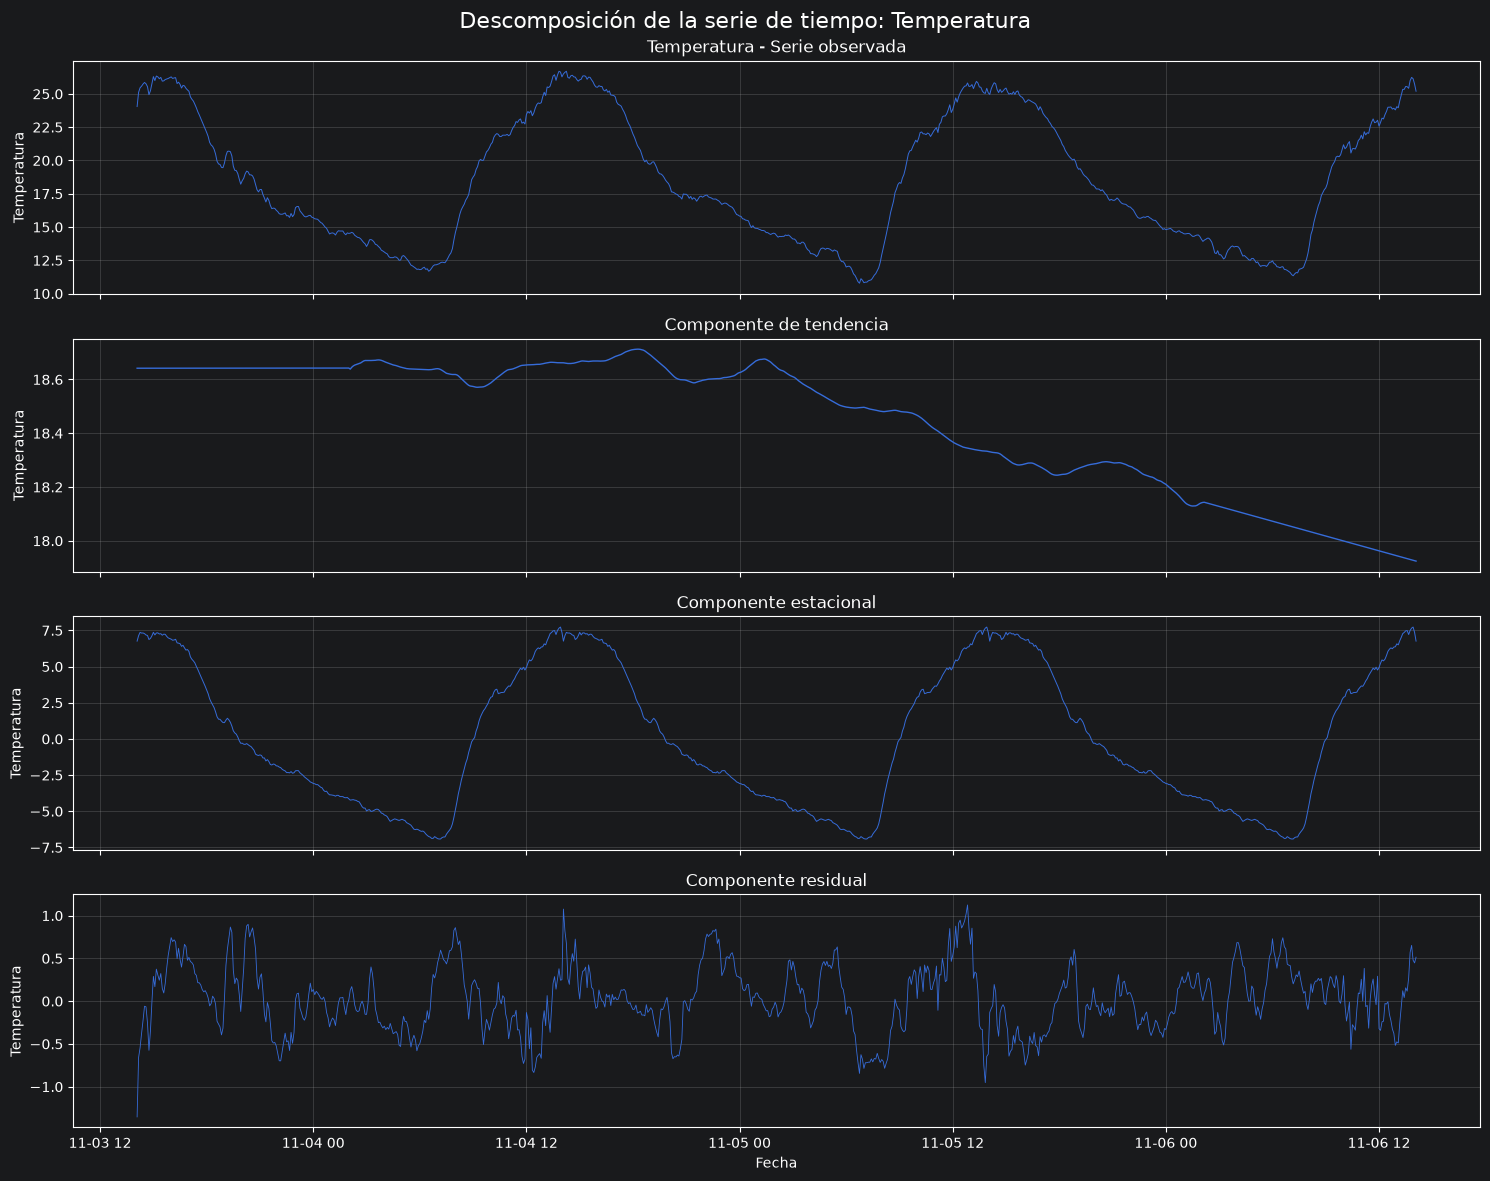

In [11]:
# ================================================================
# DESCOMPOSICIÓN DE SERIES DE TIEMPO
# Temperatura y Humedad Relativa
# Google Colab
# ================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from statsmodels.tsa.seasonal import seasonal_decompose


# ================================================================
# 1. CARGAR ARCHIVO EXCEL
# ================================================================

df = pd.read_csv("../data/datos_clima.csv")

print("Número de observaciones:", len(df))


# ================================================================
# 2. CONVERTIR FECHA Y HORA
# ================================================================

df['datetime'] = pd.to_datetime(
    df['datetime'],
    dayfirst=True,
    errors='coerce'
)

# Eliminar registros sin fecha válida
df = df.dropna(subset=['datetime'])

# Ordenar cronológicamente
df = df.sort_values('datetime')

print("\nPeriodo original:")
print("Inicio:", df['datetime'].min())
print("Final :", df['datetime'].max())


# ================================================================
# 3. SELECCIONAR VARIABLES
# ================================================================

variables = [
    'T',
]

print("\nVariables analizadas:")
for variable in variables:
    print("-", variable)


# ================================================================
# 4. CONSTRUIR SERIE TEMPORAL
# ================================================================

datos = df[
    ['datetime', 'T']
].copy()

# Establecer fecha como índice
datos = datos.set_index('datetime')


# ================================================================
# 5. ELIMINAR FECHAS DUPLICADAS
# ================================================================

# Si existen varias observaciones para el mismo instante,
# se calcula el promedio.

datos = datos.groupby(datos.index).mean()


# ================================================================
# 6. REGULARIZAR A INTERVALOS DE 5 MINUTOS
# ================================================================

datos = datos.resample('5min').mean()

print("\nNúmero de observaciones después del remuestreo:")
print(len(datos))

print("\nComprobación del nuevo índice a 5 minutos:")
display(datos.head(10)) # Si estás en Colab, display() formatea una tabla bonita


# ================================================================
# 7. IDENTIFICAR DATOS FALTANTES
# ================================================================

print("\nDatos faltantes antes de interpolar:")

for variable in variables:

    faltantes = datos[variable].isna().sum()

    porcentaje = (
        faltantes / len(datos)
    ) * 100

    print(
        f"{variable}: "
        f"{faltantes} "
        f"({porcentaje:.2f} %)"
    )


# ================================================================
# 8. INTERPOLAR DATOS FALTANTES
# ================================================================

# Interpolación basada en el tiempo

for variable in variables:

    datos[variable] = (
        datos[variable]
        .interpolate(method='time')
        .bfill()
        .ffill()
    )


# ================================================================
# 9. DEFINIR PERIODO ESTACIONAL
# ================================================================

# Datos cada 5 minutos:
#
# 12 observaciones por hora
#
# 12 * 24 = 288 observaciones por día

periodo = 288

print("\nPeriodo estacional utilizado:")
print(periodo, "observaciones")
print("Equivale a 24 horas")


# ================================================================
# 10. FUNCIÓN PARA DESCOMPONER LA SERIE
# ================================================================

def descomponer_serie(serie, nombre, unidad):

    # ------------------------------------------------------------
    # Descomposición aditiva
    # ------------------------------------------------------------

    resultado = seasonal_decompose(
        serie,
        model='additive',
        period=periodo,
        extrapolate_trend='freq'
    )

    # ------------------------------------------------------------
    # Crear DataFrame con componentes
    # ------------------------------------------------------------

    componentes = pd.DataFrame({

        'Observada': serie,

        'Tendencia':
            resultado.trend,

        'Estacional':
            resultado.seasonal,

        'Residuo':
            resultado.resid
    })

    # ------------------------------------------------------------
    # Mostrar primeras observaciones
    # ------------------------------------------------------------

    print("\n")
    print("=" * 70)
    print("DESCOMPOSICIÓN:", nombre)
    print("=" * 70)

    display(componentes.head())


    # ============================================================
    # 11. GRÁFICAS DE LAS COMPONENTES
    # ============================================================

    fig, axes = plt.subplots(
        4,
        1,
        figsize=(15, 12),
        sharex=True
    )

    # Serie original
    axes[0].plot(
        componentes.index,
        componentes['Observada'],
        linewidth=0.7
    )

    axes[0].set_title(
        f'{nombre} - Serie observada'
    )

    axes[0].set_ylabel(unidad)

    axes[0].grid(
        True,
        alpha=0.3
    )


    # Tendencia
    axes[1].plot(
        componentes.index,
        componentes['Tendencia'],
        linewidth=1
    )

    axes[1].set_title(
        'Componente de tendencia'
    )

    axes[1].set_ylabel(unidad)

    axes[1].grid(
        True,
        alpha=0.3
    )


    # Estacionalidad
    axes[2].plot(
        componentes.index,
        componentes['Estacional'],
        linewidth=0.7
    )

    axes[2].set_title(
        'Componente estacional'
    )

    axes[2].set_ylabel(unidad)

    axes[2].grid(
        True,
        alpha=0.3
    )


    # Residuo
    axes[3].plot(
        componentes.index,
        componentes['Residuo'],
        linewidth=0.6
    )

    axes[3].set_title(
        'Componente residual'
    )

    axes[3].set_ylabel(unidad)

    axes[3].set_xlabel('Fecha')

    axes[3].grid(
        True,
        alpha=0.3
    )


    plt.suptitle(
        f'Descomposición de la serie de tiempo: {nombre}',
        fontsize=16
    )

    plt.tight_layout()

    plt.show()

    return componentes


# ================================================================
# 12. DESCOMPOSICIÓN DE TEMPERATURA
# ================================================================

componentes_temperatura = descomponer_serie(

    datos['T'],

    'Temperatura',

    'Temperatura'
)


# ================================================================
# 13. DESCOMPOSICIÓN DE HUMEDAD RELATIVA
# ================================================================

# componentes_humedad = descomponer_serie(
#
#     datos['humidityAvg'],
#
#     'Humedad relativa promedio',
#
#     'Humedad relativa (%)'
# )


# ================================================================
# 14. GUARDAR COMPONENTES EN EXCEL
# ================================================================
#
# nombre_salida = 'componentes_series_temporales.xlsx'
#
# with pd.ExcelWriter(nombre_salida) as writer:
#
#     componentes_temperatura.to_excel(
#         writer,
#         sheet_name='Temperatura'
#     )
#
#     componentes_humedad.to_excel(
#         writer,
#         sheet_name='Humedad'
#     )
#

# ================================================================
# 15. DESCARGAR ARCHIVO
# ================================================================

#files.download(nombre_salida)
#print("\nArchivo generado:")
#print(nombre_salida)